# Simulate flexural waves (fourth derivatives)

A fourth-order equation, `u_tt = -kappa (u_xxxx + u_zzzz)`, written with `u.dx4` and `u.dz4` (also `u.dx2.dx2` or `u.deriv("x", 4)`). Its waves are dispersive, `omega = sqrt(kappa) |k|^2` along an axis: short waves outrun long ones, so the front spreads into a train with the shortest waves leading. Without the mixed term `2 u_xxzz` it is not the isotropic Kirchhoff plate (mixed derivatives are not supported yet): along a diagonal the waves are slower by sqrt(2), so the fronts are diamonds, farthest along the axes. Two shots run as one batch: kappa = 1 on the left, a stiff disk (kappa = 3, waves sqrt(3) faster) on the right. The fourth derivatives get no absorbing layer, so the grid is made large enough that the waves shown do not reach its edges. Dimensionless units (grid spacing 1).

In [1]:
import numpy as np
import sympy
import torch
from IPython.display import Image

from sweep.propagator.options import EagerOptions, Full
from sweep.propagator.torch import PropTorch
from sweep.symbolic import PDE, Coefficient, Eq, Field, Model, laplace

dev = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.allow_tf32 = False                 # full fp32 stencils
opts = EagerOptions(use_compile=False)

Helpers: a Ricker wavelet, a run that keeps snapshots, and a GIF writer.

In [2]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter


def ricker(nt, dt, f0):
    a = (np.pi * f0 * (np.arange(nt) * dt - 1.5 / f0)) ** 2
    return torch.tensor((1 - 2 * a) * np.exp(-a), dtype=torch.float32)


def snapshots(solver, wavelet, sources, receivers, models, every=10, **kwargs):
    """Run one batch; return the record, every field every `every` steps (cropped to the model) and the times."""
    steps = list(range(every - 1, solver.nt, every))
    with torch.no_grad():
        record, snap = solver(wavelet, sources, receivers, models=models, return_wavefield=True,
                              snapshot_times=steps, **kwargs)
    nz, nx = models[0].shape[-2:]
    x0, _, z0, _ = solver._runtime_padding()
    if snap.shape[-2] - nz < z0 or snap.shape[-1] - nx < x0:   # padding not as reported: centre the crop
        z0, x0 = (snap.shape[-2] - nz) // 2, (snap.shape[-1] - nx) // 2
    snap = snap[..., z0:z0 + nz, x0:x0 + nx]
    names = [f.name for f in solver.equation.field_specs]
    frames = {n: snap[:, i, :, 0].numpy() for i, n in enumerate(names) if not n.startswith("_")}
    return record.cpu(), frames, (np.array(steps) + 1) * float(solver.dt)


def save_gif(path, panels, times, extent, xlabel="x (km)", ylabel="z (km)", unit="s", cmap="seismic",
             clip=99.8, outline=None, normalize=False):
    """Animate panels [(title, frames (nframe, nz, nx))] with fixed colour limits; outline: a model drawn as contours."""
    aspect = abs(extent[1] - extent[0]) / abs(extent[2] - extent[3])
    fig, axes = plt.subplots(1, len(panels), figsize=((3.2 * aspect + 0.45) * len(panels), 3.6),
                             squeeze=False, constrained_layout=True)
    outlines = outline if isinstance(outline, list) else [outline] * len(panels)
    images = []
    for k, (ax, (title, data), line) in enumerate(zip(axes[0], panels, outlines)):
        if normalize:
            data = data / np.abs(data).max(axis=(1, 2), keepdims=True).clip(min=1e-30)
        if cmap == "seismic":
            a = np.percentile(np.abs(data), clip) or 1.0
            lo, hi = -a, a
        else:
            lo, hi = np.percentile(data, [100 - clip, clip])
        im = ax.imshow(data[0], cmap=cmap, vmin=lo, vmax=hi, extent=extent, interpolation="bilinear")
        if line is not None:
            ax.contour(line, levels=6, colors="k", linewidths=0.5, alpha=0.35, extent=extent, origin="upper")
        ax.set(title=title, xlabel=xlabel)
        if k == 0:
            ax.set_ylabel(ylabel)
        else:
            ax.tick_params(labelleft=False)
        images.append((im, data))
    clock = fig.suptitle("")

    def draw(i):
        for im, data in images:
            im.set_data(data[i])
        clock.set_text(f"t = {times[i]:.3g} {unit}")

    FuncAnimation(fig, draw, frames=len(times)).save(path, writer=PillowWriter(fps=10), dpi=70)
    plt.close(fig)
    return path

## The PDE

Declare the models and fields, write one equation per field, and build the equation class.

In [3]:
kappa = Model("kappa")
u = Field("u", source=True, receiver=True)

pde = PDE([Eq(u.dt2, -kappa * (u.dx4 + u.dz4))], name="Flexural")
Flexural = pde.build(ndim=2)
pde

PDE([Eq(u.dt2, -kappa*(u.dx4 + u.dz4))], name='Flexural')

## Run it

A model, a propagator, one shot; a snapshot of every field is kept at regular steps.

In [4]:
# Leapfrog is stable for dt <= 2 h^2 / sqrt(kappa_max * 2 * 39.7) (39.7: the largest value
# of the order-8 fourth-derivative stencil, reached along both axes at once): 0.13 here.
n, h, dt, nt, f0 = 241, 1.0, 0.1, 1950, 0.02
z, x = np.mgrid[0:n, 0:n]
disk = ((z - 120) ** 2 + (x - 165) ** 2 < 22**2).astype(np.float32)
kappa_b = torch.stack([torch.ones(n, n), torch.tensor(1.0 + 2.0 * disk)]).to(dev)

solver = PropTorch(Flexural(8, device=dev), shape=(n, n), dh=h, dt=dt, nt=nt, dev=dev,
                   impl="eager", memory=Full(), eager_options=opts)
src = np.array([[n // 2, n // 2]] * 2)
rec = np.array([[[n // 2, n // 2]]] * 2)
record, frames, t = snapshots(solver, ricker(nt, dt, f0), src, rec, [kappa_b], every=44,
                              max_vel=1.0, pml_freq=f0)
assert torch.isfinite(record).all()

## The wavefield

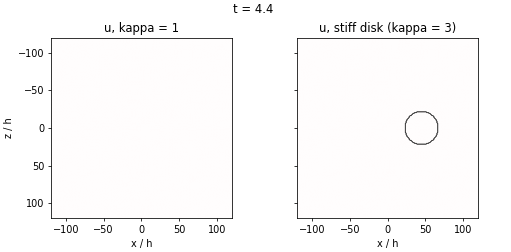

In [5]:
r = (n - 1) * h / 2
ext = [-r, r, r, -r]
gif = save_gif("73_symbolic_flexural.gif", [("u, kappa = 1", frames["u"][:, 0]),
                                ("u, stiff disk (kappa = 3)", frames["u"][:, 1])],
               t, ext, xlabel="x / h", ylabel="z / h", unit="", outline=[None, disk])
Image(filename=gif)